# Analise Exploratoria de Dados (EDA)

**Hipoteses de negocio a serem avaliadas:**

1) **Hipotese de segmentacao por porte do locador:** Imoveis de anfitrioes com portfolios grandes (multiplos anuncios) formam um segmento distinto daqueles operados por anfitrioes de imovel unico, tanto em precificacao quanto em disponibilidade. *Features: `calculated_host_listings_count`, `availability_365`, `price`.* Um segmento de "operadores profissionais" teria valor comercial para politicas de parceria e priorizacao de suporte.

2) **Hipotese de segmentacao por tipo de acomodacao e localizacao:** Quartos privados em bairros perifericos (Queens, Brooklyn) apresentam perfil comercial diferente de apartamentos inteiros em Manhattan, com padroes distintos de preco, estadia minima e rotatividade de hospedes. *Features: `room_type`, `neighbourhood_group`, `price`, `minimum_nights`, `reviews_per_month`.* Identificar esses perfis permite adequar estrategias de comunicacao e precificacao por regiao.

3) **Hipotese de segmentacao por sazonalidade e maturidade do anuncio:** Anuncios com alta disponibilidade anual e muitas avaliacoes acumuladas (imoveis maduros e ativos ha mais tempo) formam um grupo diferente de anuncios recem-criados ou com baixa atividade, refletindo estagios distintos no ciclo de vida do anuncio na plataforma. *Features: `availability_365`, `number_of_reviews`, `reviews_per_month`, `meses_ativos`.* Compreender o ciclo de vida permite acoes de retencao e reativacao de anuncios.

---

### Sumário

| Seção | Tópico |
| :--- | :--- |
| [1.0](#1.0) | Configuração do Ambiente |
| [2.0](#2.0) | Análise de Nulos, Valores Únicos e Duplicatas |
| [3.0](#3.0) | Entendendo o Dataset e as Features |
| [4.0](#4.0) | Análise de Features — `price` e demais numéricas |
| [5.0](#5.0) | Feature Engineering — encoding, features derivadas, exportação |

___

## 1.0 Configuracao do Ambiente

> **Parametrização e Reprodutibilidade (`configs.yaml`):**
> - **Arquivo bruto (`data.raw_dir` / `data.raw_filename`):** `data/raw/AB_NYC_2019.csv`
> - **Diretório de saída (`data.processed_dir` / `data.processed_filename`):** `data/processed/master.csv`
> - **Filtro de sanidade (`preprocessing.min_price_filter`):** remoção de registros com `price <= 0` (anúncios com erro de cadastro ou valor zerado, que inviabilizam o cálculo de ticket e transformação logarítmica).


In [ ]:
import os
import sys
import warnings
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.preprocessing import RobustScaler
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath(".."))
%load_ext autoreload
%autoreload 2

from src.config import carregar_configs
from src.plot_figs import histograma_simples, plot_boxplot_outliers, plot_distribuicao, plot_matriz_correlacao
from src.profiling import resumo_estatistico, resumo_estatistico_numerico, analisar_multicolinearidade_pares

cfg = carregar_configs()
warnings.filterwarnings("ignore")


In [172]:
# Configurando os diretórios via configs.yaml:
# - raw_dir: "data/raw" | raw_filename: "AB_NYC_2019.csv"
# - processed_dir: "data/processed" | processed_filename: "master.csv"

nome_arquivo = cfg["data"]["raw_filename"]  # "AB_NYC_2019.csv"
DIR_ATUAL = os.getcwd()
DIR_ARQ = os.path.join(DIR_ATUAL, "..", cfg["data"]["raw_dir"], nome_arquivo)
DIR_EXP = os.path.join(DIR_ATUAL, "..", cfg["data"]["processed_dir"])

df = pd.read_csv(DIR_ARQ)


In [173]:
# Filtro de registros inválidos parametrizado pelo configs.yaml
# Consideração adotada: min_price_filter = 0 (remove anúncios com diária <= US$ 0,
# pois preços nulos/zerados representam erros de preenchimento e distorcem escalas logarítmicas)
min_price = cfg["preprocessing"]["min_price_filter"]  # Valor: 0
n_antes = len(df)
df = df[df["price"] > min_price].copy()
n_removidos = n_antes - len(df)
print(f"{n_removidos} registros com price <= {min_price} removidos ({n_removidos / n_antes * 100:.2f}% da base).")


11 registros com price <= 0 removidos (0.02% da base).


In [174]:
df.head(20)

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
5,5099,Large Cozy 1 BR Apartment In Midtown East,7322,Chris,Manhattan,Murray Hill,40.74767,-73.97500,Entire home/apt,200,3,74,2019-06-22,0.59,1,129
6,5121,BlissArtsSpace!,7356,Garon,Brooklyn,Bedford-Stuyvesant,40.68688,-73.95596,Private room,60,45,49,2017-10-05,0.40,1,0
7,5178,Large Furnished Room Near B'way,8967,Shunichi,Manhattan,Hell's Kitchen,40.76489,-73.98493,Private room,79,2,430,2019-06-24,3.47,1,220
8,5203,Cozy Clean Guest Room - Family Apt,7490,MaryEllen,Manhattan,Upper West Side,40.80178,-73.96723,Private room,79,2,118,2017-07-21,0.99,1,0
9,5238,Cute & Cozy Lower East Side 1 bdrm,7549,Ben,Manhattan,Chinatown,40.71344,-73.99037,Entire home/apt,150,1,160,2019-06-09,1.33,4,188


In [175]:
df.info()

<class 'pandas.DataFrame'>
Index: 48884 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48884 non-null  int64  
 1   name                            48868 non-null  str    
 2   host_id                         48884 non-null  int64  
 3   host_name                       48863 non-null  str    
 4   neighbourhood_group             48884 non-null  str    
 5   neighbourhood                   48884 non-null  str    
 6   latitude                        48884 non-null  float64
 7   longitude                       48884 non-null  float64
 8   room_type                       48884 non-null  str    
 9   price                           48884 non-null  int64  
 10  minimum_nights                  48884 non-null  int64  
 11  number_of_reviews               48884 non-null  int64  
 12  last_review                     38833 non-null  

>
> **16 colunas totais**
>
> **48.895 dados**
>
> `6 features categóricas`
>
> `10 features numéricas`

___
 
## 2.0 Análise de Nulos, Valores Únicos e Duplicatas


In [176]:
# quantidade de valores únicos:

dic = {}

for coluna in df.columns:

    unicos = len(df[coluna].unique())

    dic[coluna] = unicos


df_unicos = pd.Series(dic, name='quantidade_unicos').to_frame()

df_unicos.sort_values(by ='quantidade_unicos', ascending = True)


,quantidade_unicos
room_type,3
neighbourhood_group,5
calculated_host_listings_count,47
minimum_nights,109
neighbourhood,221
availability_365,366
number_of_reviews,394
price,673
reviews_per_month,938
last_review,1765


>
> **todos os ID são diferentes**
>
>
> `room_type e neighbourhood_group` possuem **poucos valores únicos**, podem garantir bom poder de agrupamento
>
>
>

In [177]:
df['neighbourhood_group'].value_counts()

neighbourhood_group
Manhattan        21660
Brooklyn         20095
Queens            5666
Bronx             1090
Staten Island      373
Name: count, dtype: int64

In [178]:
df['room_type'].value_counts()

room_type
Entire home/apt    25407
Private room       22319
Shared room         1158
Name: count, dtype: int64

>
> Veja que as colunas de `room_type` possuem um **valor quualitativo**
>
> - Claro que Entire_HOme é melhor que Private que é melhor que Shared Room 
> 
> **Podemos atribuir um ordinal encoding interesante**
>

In [179]:
# quantidade de nulos em cada feature

dic = {}

for coluna in df.columns:

    total = df[coluna].shape[0]

    nao_nulos = df[coluna].dropna().shape[0]

    dif = total-nao_nulos

    dic[coluna] = dif

df_nulos = pd.Series(dic, name='quantidade_nulos').to_frame()

df_nulos.sort_values(by = 'quantidade_nulos', ascending = False)



,quantidade_nulos
last_review,10051
reviews_per_month,10051
host_name,21
name,16
neighbourhood_group,0
neighbourhood,0
id,0
host_id,0
longitude,0
latitude,0


>
> As features **last_review e reviews_per_month**  tem muitos valores nulos.
>
> `Reviews_per_month pode sofrer o fill de nulos com o zero`, mas **last_review não, pois o zero indica um valor qualitativo enorme**
>

In [180]:
# Verificação de registros duplicados na base

duplicatas_exatas = df.duplicated().sum()
duplicatas_chaves = df.duplicated(subset=["name", "host_id", "latitude", "longitude"]).sum()

df_duplicatas = pd.DataFrame({
    "Critério": ["Linhas 100% idênticas", "Mesmo anúncio/host/coordenadas"],
    "Quantidade de Duplicatas": [duplicatas_exatas, duplicatas_chaves]
})

display(df_duplicatas)


,Critério,Quantidade de Duplicatas
0,Linhas 100% idênticas,0
1,Mesmo anúncio/host/coordenadas,0


___

## 3.0 Entendendo o Dataset e as Features

Avaliando cada feature original para definir as regras de negócio e pré-processamento consolidadas no `configs.yaml`:

| Feature | Análise Exploratória | Ação / Tratamento Adotado (`configs.yaml`) |
| :--- | :--- | :--- |
| `id`, `name`, `host_id`, `host_name` | Identificadores únicos e textos livres. Altíssima cardinalidade, sem significado métrico para distância | **Remover** (`drop_cols`) |
| `neighbourhood_group` | Macro-região (5 distritos: Bronx, Brooklyn, Manhattan, Queens, Staten Island). Forte poder de segmentação espacial | **One-Hot Encoding** (`onehot_cols`, com `drop_first=True` tendo `Bronx` como referência) |
| `neighbourhood` | Bairro específico (>220 categorias). Causaria explosão de dimensionalidade e esparsidade | **Remover** (`drop_cols` — já representado por `latitude`, `longitude`, distância e distrito) |
| `latitude` e `longitude` | Coordenadas geográficas exatas. Úteis para derivar distância ao centro turístico e plotagem em mapa | **Manter em `geo_cols`** e criar `distancia_Times_Square_log` |
| `room_type` | Tipo de acomodação (3 categorias com hierarquia clara de espaço/privacidade) | **Ordinal Encoding** (`"Shared room": 0`, `"Private room": 1`, `"Entire home/apt": 2`) |
| `price` | Diária em US$. Assimetria extrema à direita (cauda longa) | **Transformação `np.log1p`** (`price_log`) + compor `custo_estadia_log`; remover `price` bruto |
| `minimum_nights` | Estadia mínima exigida. Presença de outliers (locações mensais/anuais) | **Transformação `np.log1p`** + compor `custo_estadia_log`; descartada depois por colinearidade (`|r| >= 0.70`) |
| `number_of_reviews` | Total histórico de avaliações acumuladas | **Transformação `np.log1p`** + compor `meses_ativo_log`; descartada depois por colinearidade (`|r| >= 0.70`) |
| `last_review` | Data da última avaliação (~20,6% de nulos em imóveis sem review) | **Remover** (`drop_cols` — maturidade capturada via `meses_ativo_log`) |
| `reviews_per_month` | Giro mensal de hóspedes. Nulos correspondem a anúncios com `number_of_reviews == 0` | **Imputar `0` nos nulos** (`fill_nulls_zero_cols`) + **Transformação `np.log1p`** (`reviews_per_month_log`) |
| `calculated_host_listings_count` | Total de anúncios do mesmo anfitrião (separa anfitrião casual de operador profissional) | **Transformação `np.log1p`** + compor `volume_oferta_dias_anfitriao_log`; descartada depois por colinearidade |
| `availability_365` | Dias disponíveis nos próximos 365 dias (0 a 365). Assimetria baixa (0,76) | **Manter em escala original** (`numerical_model_cols`) + compor `volume_oferta_dias_anfitriao_log` |


___

## 4.0 Análise de Features

### 4.1 Analisando `price`

In [181]:
resumo_estatistico(df,coluna = 'price')

,Métrica,Valor
0,Média,152.76
1,Mediana,106.00
2,Desvio Padrão,240.17
3,Mínimo,10.00
4,1º Quartil (Q1 - 25%),69.00
5,3º Quartil (Q3 - 75%),175.00
6,Intervalo Interquartil (IQR),106.00
7,Máximo,"10,000.00"
8,Assimetria (Skewness),19.12
9,Curtose (Kurtosis),585.64


>
> Assimetria positiva de **19.12**, extremamente positiva,  indica presença de consideráveis outliers a **direita da curva**
>
> Veja que o **desvio padrão é alto**, e a **média é consideravelmente diferente da mediana**
> 
> `Alta curtose, indicando pico agudo do KDE.`
>

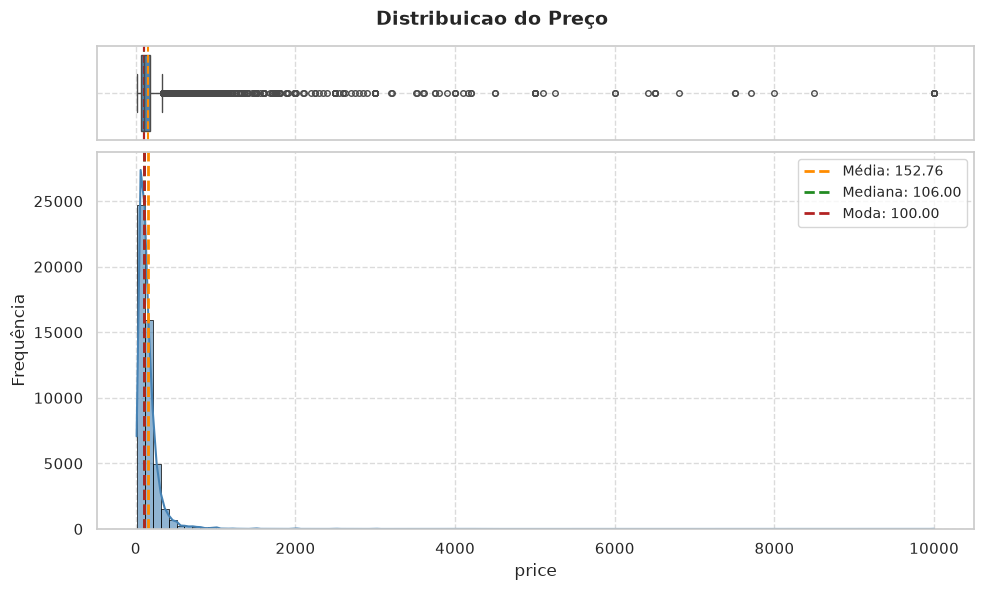

In [182]:
histograma_simples(df,coluna = 'price',bins = 100,titulo = 'Distribuicao do Preço')

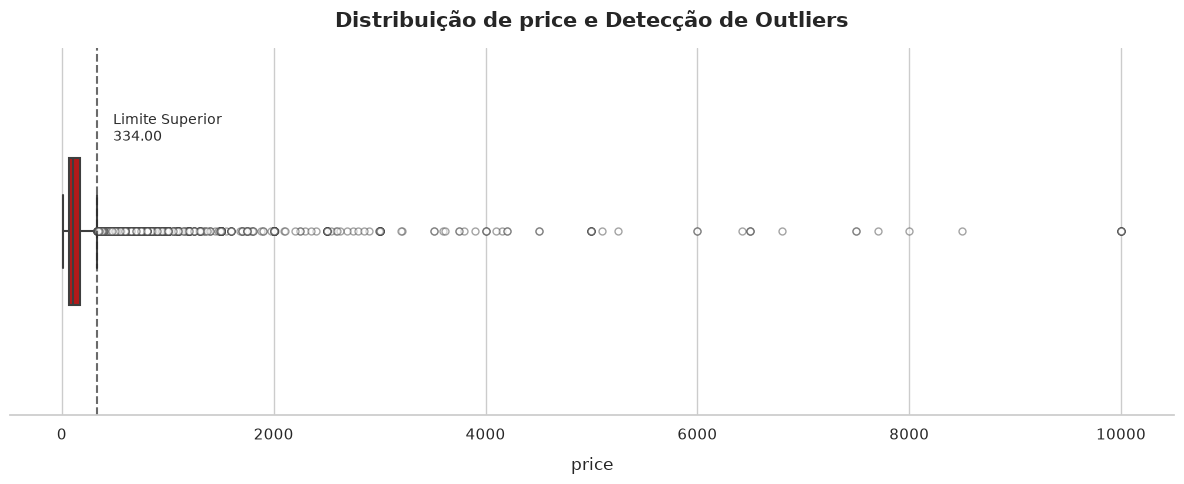

--- Diagnóstico de Outliers: price ---
Limite Superior (Q3 + 1.5*IQR): 334.00
Limite Inferior (Q1 - 1.5*IQR): -90.00
Outliers Superiores: 2972 registros
Outliers Inferiores: 0 registros
Total de Outliers: 2972 (6.08%)


In [183]:
# quantos outliers?
plot_boxplot_outliers(df,coluna = 'price', cor = '#CD0000')

>
> **Muitos outliers, mas todos a direita**
> 

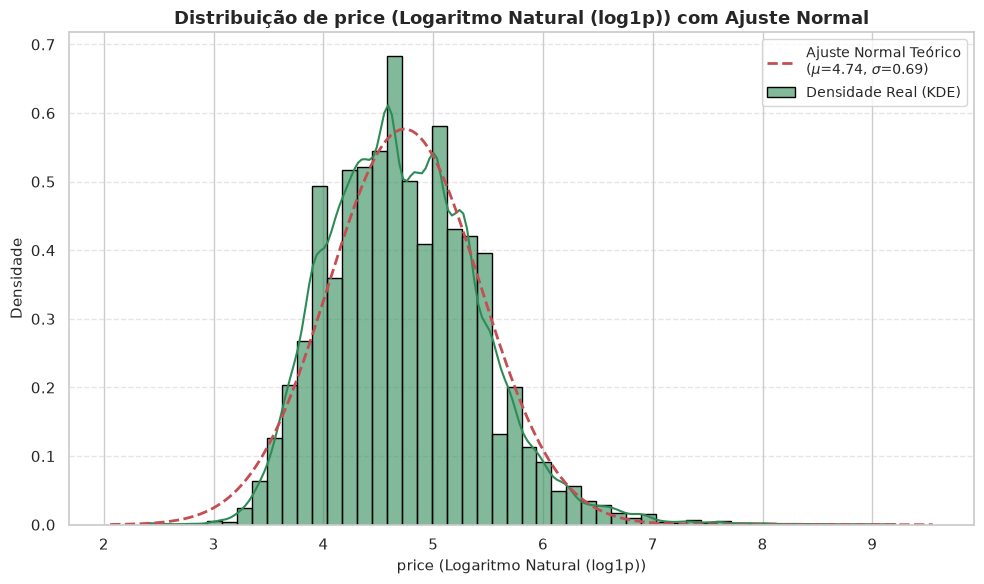

,Transformação,Média,Mediana,Desvio Padrão,Assimetria (Skew),Curtose (Kurt)
0,Logaritmo Natural (log1p),4.7380,4.6728,0.6918,0.6294,1.3436


In [184]:
plot_distribuicao(df,coluna = 'price', transformacao = 'log1p')

>
> **Veja que a transformação logaritmica reduziu absurdamente a assimetria e curtose**
>
> `Será que os outros dados do dataset também possuem essa distribuição tipicamente lognormal?`

>
>

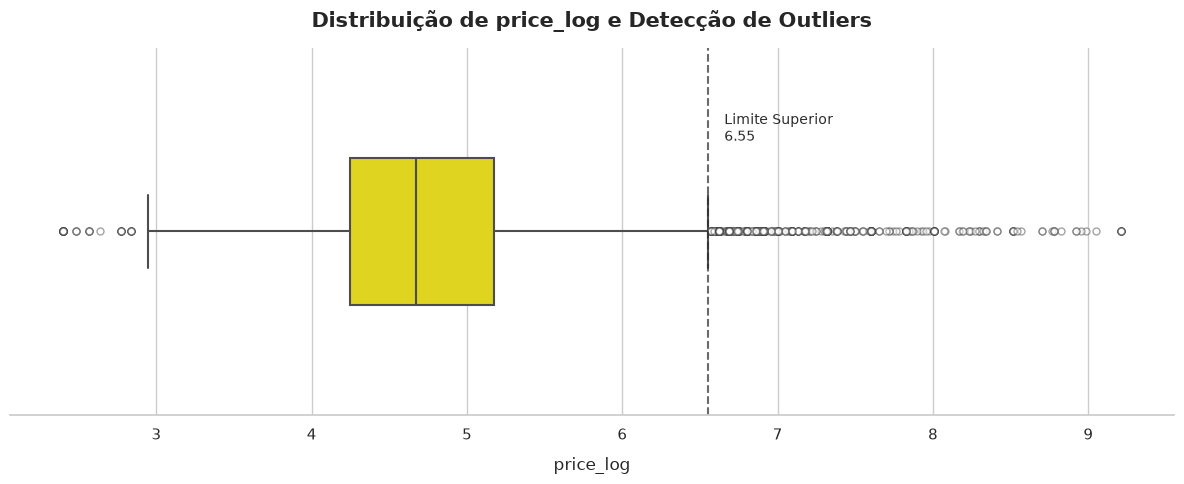

--- Diagnóstico de Outliers: price_log ---
Limite Superior (Q3 + 1.5*IQR): 6.55
Limite Inferior (Q1 - 1.5*IQR): 2.87
Outliers Superiores: 589 registros
Outliers Inferiores: 37 registros
Total de Outliers: 626 (1.28%)


In [185]:
df['price_log'] = np.log1p(df['price']) 

plot_boxplot_outliers(df,coluna = 'price_log',cor = "#FFF000")

>
> **4x menos outliers, IQR controlado**
> 

### 4.2 Análise Conjunta das Demais Features Numéricas

>
> Avaliação de `number_of_reviews`, `reviews_per_month`,
> `calculated_host_listings_count` e `availability_365`.
>
> A assimetria elevada dessas variáveis (assim como `price`) justifica a transformação logarítmica
> para viabilizar o uso em algoritmos baseados em distância euclidiana.
>

In [186]:
colunas = [
    'minimum_nights',
    'number_of_reviews',
    'reviews_per_month',
    'calculated_host_listings_count',
    'availability_365'
]

df_analise = df[colunas]


resumo_estatistico_numerico(df_analise)

,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
Média,7.03,23.27,1.37,7.14,112.78
Mediana,3.00,5.00,0.72,1.00,45.00
Desvio Padrão,20.51,44.55,1.68,32.96,131.63
Mínimo,1.00,0.00,0.01,1.00,0.00
1º Quartil (Q1 - 25%),1.00,1.00,0.19,1.00,0.00
3º Quartil (Q3 - 75%),5.00,24.00,2.02,2.00,227.00
Intervalo Interquartil (IQR),4.00,23.00,1.83,1.00,227.00
Máximo,"1,250.00",629.00,58.50,327.00,365.00
Assimetria (Skewness),21.83,3.69,3.13,7.93,0.76
Curtose (Kurtosis),853.98,19.53,42.51,67.53,-1.00


>
>
> Veja que exceto **avaliability** a `assimetria de todas as outras features numéricas são bizarramente altas`, presença clara de outliers pela diferença de médias e medianas.
>
> **vamos aplicar o log1p de modo a reduzir a assimetria**
>
> Estratégia de usar a modelagem de `distribuição lognormal`

___

## 5.0 Feature Engineering

> Todas as escolhas de transformação, codificação, criação de variáveis e descarte de colinearidade abaixo são parametrizadas pelo arquivo `configs.yaml` (seção `preprocessing`), garantindo total reprodutibilidade entre a EDA e o pipeline de produção (`src/preprocessing.py`).


### 5.1 Tratamento de Nulos e Transformação Logarítmica

> **Parâmetros adotados (`configs.yaml` -> `preprocessing`):**
> - **`fill_nulls_zero_cols`: `["reviews_per_month"]`**
>   - *Consideração:* Os 10.052 valores nulos em `reviews_per_month` ocorrem exatamente quando `number_of_reviews == 0`. Portanto, a imputação com `0` representa fielmente a ausência de fluxo mensal de avaliações.
> - **`log_transform_cols`: `["price", "minimum_nights", "number_of_reviews", "reviews_per_month", "calculated_host_listings_count"]`**
>   - *Consideração:* Todas essas 5 variáveis exibem distribuição fortemente assimétrica à direita (comportamento log-normal). A aplicação de `np.log1p(x) = ln(1 + x)` (que suporta valores zero sem indefinir) comprime outliers severos e estabiliza a variância para algoritmos baseados em distância euclidiana.
>   - *Exceção explícita:* `availability_365` **não** recebe transformação logarítmica pois já é limitada ao intervalo `[0, 365]` e possui assimetria moderada (`0.76`).


In [187]:
# 1. Tratamento de nulos antes do log conforme configs.yaml:
# fill_nulls_zero_cols = ["reviews_per_month"] -> preenche com 0 imóveis sem avaliações
for col_null in cfg["preprocessing"]["fill_nulls_zero_cols"]:
    df[col_null] = df[col_null].fillna(0)

# 2. Lista das 5 features numéricas assimétricas que recebem np.log1p (configs.yaml):
# log_transform_cols = [
#     "price",
#     "minimum_nights",
#     "number_of_reviews",
#     "reviews_per_month",
#     "calculated_host_listings_count"
# ]
features_log = cfg["preprocessing"]["log_transform_cols"]

novas_colunas_log = []
for col in features_log:
    col_log = f"{col}_log"
    df[col_log] = np.log1p(df[col])
    novas_colunas_log.append(col_log)

df_analise = df[novas_colunas_log]
resumo_estatistico_numerico(df_analise)


,price_log,minimum_nights_log,number_of_reviews_log,reviews_per_month_log,calculated_host_listings_count_log
Média,4.74,1.50,1.99,0.54,1.09
Mediana,4.67,1.39,1.79,0.31,0.69
Desvio Padrão,0.69,0.87,1.56,0.58,0.86
Mínimo,2.40,0.69,0.00,0.00,0.69
1º Quartil (Q1 - 25%),4.25,0.69,0.69,0.04,0.69
3º Quartil (Q3 - 75%),5.17,1.79,3.22,0.95,1.10
Intervalo Interquartil (IQR),0.92,1.10,2.53,0.91,0.41
Máximo,9.21,7.13,6.45,4.09,5.79
Assimetria (Skewness),0.63,1.50,0.36,0.95,3.28
Curtose (Kurtosis),1.34,1.98,-0.93,-0.11,11.80


In [188]:
df.info()

<class 'pandas.DataFrame'>
Index: 48884 entries, 0 to 48894
Data columns (total 21 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id                                  48884 non-null  int64  
 1   name                                48868 non-null  str    
 2   host_id                             48884 non-null  int64  
 3   host_name                           48863 non-null  str    
 4   neighbourhood_group                 48884 non-null  str    
 5   neighbourhood                       48884 non-null  str    
 6   latitude                            48884 non-null  float64
 7   longitude                           48884 non-null  float64
 8   room_type                           48884 non-null  str    
 9   price                               48884 non-null  int64  
 10  minimum_nights                      48884 non-null  int64  
 11  number_of_reviews                   48884 non-null  int64

>
> **Estamos trabalhando com 20 colunas, vamos agora fazer a remoção inicial das features e determinados encondings**
> 
> `Devemos tratar as features categóricas`
>
> `Devemos remover as colunas já transformadas em log1p`

In [189]:
df_tratado = df.copy()

### 5.2 Remoção de Features e Encoding

> **Parâmetros e considerações adotadas (`configs.yaml` -> `preprocessing`):**
>
> 1. **Ordinal Encoding (`ordinal_room_type_map`):**
>    - `"Shared room": 0` | `"Private room": 1` | `"Entire home/apt": 2`
>    - *Justificativa:* Existe uma ordem intrínseca de privacidade, área exclusiva e valor comercial entre quarto compartilhado, quarto privativo e imóvel inteiro.
>
> 2. **One-Hot Encoding (`onehot_cols`: `["neighbourhood_group"]`, com `drop_first=True`):**
>    - Gera 4 colunas binárias (`0` ou `1`): `neighbourhood_group_Brooklyn`, `neighbourhood_group_Manhattan`, `neighbourhood_group_Queens` e `neighbourhood_group_Staten Island`.
>    - *Justificativa:* O distrito **`Bronx`** (primeiro em ordem alfabética) torna-se a categoria de referência implícita (todas as 4 dummies iguais a `0`), evitando colinearidade perfeita no espaço de features.
>
> 3. **Descarte Inicial de 11 Colunas (`drop_cols`):**
>    - **Identificadores / textos sem valor geométrico (4):** `id`, `name`, `host_id`, `host_name`
>    - **Sub-bairro de alta cardinalidade (1):** `neighbourhood` (mais de 220 categorias; a localização já está contemplada pelas coordenadas e macro-distrito)
>    - **Data bruta com >20% de nulos (1):** `last_review` (substituída pela feature contínua de maturidade `meses_ativo_log`)
>    - **Variáveis originais já convertidas para escala logarítmica (5):** `price`, `minimum_nights`, `number_of_reviews`, `reviews_per_month`, `calculated_host_listings_count` (removidas para evitar duplicidade de informação com suas versões `_log`).


In [190]:
# Tratamento de Features e Remoção via configs.yaml

# (1) Ordinal Encoding em room_type:
# Mapa adotado: {"Shared room": 0, "Private room": 1, "Entire home/apt": 2}
mapa = cfg["preprocessing"]["ordinal_room_type_map"]
df_tratado["room_type"] = df_tratado["room_type"].map(mapa)

# (2) One-Hot Encoding em neighbourhood_group (onehot_cols = ["neighbourhood_group"]):
# drop_first=True remove "neighbourhood_group_Bronx" (categoria base = 0 nas 4 dummies restantes)
df_tratado = pd.get_dummies(
    df_tratado,
    columns=cfg["preprocessing"]["onehot_cols"],
    drop_first=True,
    dtype=int,
)

# (3) Remoção das 11 colunas definidas em drop_cols:
# - IDs/Textos: ["id", "name", "host_id", "host_name"]
# - Categórica granular / Data: ["neighbourhood", "last_review"]
# - Originais substituídas por _log: ["price", "minimum_nights", "number_of_reviews",
#                                     "reviews_per_month", "calculated_host_listings_count"]
colunas_remover = cfg["preprocessing"]["drop_cols"]
df_tratado = df_tratado.drop(columns=colunas_remover)

# Diagnóstico após encoding e remoção inicial
df_tratado.info()


<class 'pandas.DataFrame'>
Index: 48884 entries, 0 to 48894
Data columns (total 13 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   latitude                            48884 non-null  float64
 1   longitude                           48884 non-null  float64
 2   room_type                           48884 non-null  int64  
 3   availability_365                    48884 non-null  int64  
 4   price_log                           48884 non-null  float64
 5   minimum_nights_log                  48884 non-null  float64
 6   number_of_reviews_log               48884 non-null  float64
 7   reviews_per_month_log               48884 non-null  float64
 8   calculated_host_listings_count_log  48884 non-null  float64
 9   neighbourhood_group_Brooklyn        48884 non-null  int64  
 10  neighbourhood_group_Manhattan       48884 non-null  int64  
 11  neighbourhood_group_Queens          48884 non-null  int64

### 5.3 Criação de Features Derivadas

> **Features compostas engenheiradas para capturar sinergias operacionais e espaciais (`configs.yaml`):**
>
> 1. **`distancia_Times_Square_log`** (`reference_landmark`: **Times Square**, `lat = 40.7580`, `lon = -73.9855`, `earth_radius_km = 6371.0`):
>    - Calcula a distância geodésica exata em quilômetros (fórmula de Haversine, corrigindo a curvatura terrestre) de cada imóvel até o epicentro turístico/comercial de Manhattan, seguida de `np.log1p`.
> 2. **`custo_estadia_log`** (`np.log1p(price * minimum_nights)`):
>    - Representa o **ticket mínimo de desembolso** exigido do hóspede para reservar o imóvel (diferenciando diárias altas de estadias curtas vs. diárias moderadas que exigem locação mensal).
> 3. **`volume_oferta_dias_anfitriao_log`** (`np.log1p(availability_365 * calculated_host_listings_count)`):
>    - Mede a **capacidade operacional anual do anfitrião** (estoque de dias-imóvel ofertados no mercado), separando moradores casuais de grandes gestoras e redes hoteleiras.
> 4. **`meses_ativo_log`** (`np.log1p(number_of_reviews / (reviews_per_month + 1e-6))`):
>    - Estima a **maturidade/tempo de vida ativa** do anúncio na plataforma em meses (para imóveis sem avaliações, resulta em `0`).


In [191]:
# Criação de Features Derivadas (parametrizada via configs.yaml)

# (1) Distância de Haversine até o ponto de referência (Times Square):
# reference_landmark = {"name": "Times Square", "lat": 40.7580, "lon": -73.9855, "earth_radius_km": 6371.0}
lm = cfg["preprocessing"]["reference_landmark"]
R = lm["earth_radius_km"]          # 6371.0 km
ts_lat, ts_lon = lm["lat"], lm["lon"]  # 40.7580, -73.9855

dlat = np.radians(df_tratado["latitude"] - ts_lat)
dlon = np.radians(df_tratado["longitude"] - ts_lon)
a = (
    np.sin(dlat / 2) ** 2
    + np.cos(np.radians(ts_lat)) * np.cos(np.radians(df_tratado["latitude"])) * np.sin(dlon / 2) ** 2
)
df_tratado["distancia_Times_Square_log"] = np.log1p(R * 2 * np.arctan2(np.sqrt(a), np.sqrt(1 - a)))

# (2) Ticket mínimo da estadia (diária × noites mínimas) em escala log1p
df_tratado["custo_estadia_log"] = np.log1p(df["price"] * df["minimum_nights"])

# (3) Porte operacional do anfitrião (disponibilidade anual × nº de imóveis do host) em escala log1p
df_tratado["volume_oferta_dias_anfitriao_log"] = np.log1p(
    df["availability_365"] * df["calculated_host_listings_count"]
)

# (4) Tempo estimado de atividade/maturidade do anúncio em meses (total reviews / reviews por mês) em escala log1p
df_tratado["meses_ativo_log"] = np.log1p(df["number_of_reviews"] / (df["reviews_per_month"] + 1e-6))


In [192]:
df_tratado.head(20)

,latitude,longitude,room_type,availability_365,price_log,minimum_nights_log,number_of_reviews_log,reviews_per_month_log,calculated_host_listings_count_log,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,distancia_Times_Square_log,custo_estadia_log,volume_oferta_dias_anfitriao_log,meses_ativo_log
0,40.64749,-73.97237,1,365,5.010635,0.693147,2.302585,0.190620,1.945910,1,0,0,0,2.590609,5.010635,7.692113,3.780933
1,40.75362,-73.98377,2,355,5.420535,0.693147,3.828641,0.322083,1.098612,0,1,0,0,0.411027,5.420535,6.566672,4.782653
2,40.80902,-73.94190,1,365,5.017280,1.386294,0.000000,0.000000,0.693147,0,1,0,0,2.048627,6.111467,5.902633,0.000000
3,40.68514,-73.95976,2,194,4.499810,0.693147,5.602119,1.729884,0.693147,1,0,0,0,2.239329,4.499810,5.273000,4.080747
4,40.79851,-73.94399,2,0,4.394449,2.397895,2.302585,0.095310,0.693147,0,1,0,0,1.902331,6.685861,0.000000,4.510850
5,40.74767,-73.97500,2,129,5.303305,1.386294,4.317488,0.463734,0.693147,0,1,0,0,0.895967,6.398595,4.867534,4.839638
6,40.68688,-73.95596,1,0,4.110874,3.828641,3.912023,0.336472,0.693147,1,0,0,0,2.229019,7.901377,0.000000,4.816239
7,40.76489,-73.98493,1,220,4.382027,1.098612,6.066108,1.497388,0.693147,0,1,0,0,0.569643,5.068904,5.398163,4.827668
8,40.80178,-73.96723,1,0,4.382027,1.098612,4.779123,0.688135,0.693147,0,1,0,0,1.809171,5.068904,0.000000,4.789089
9,40.71344,-73.99037,2,188,5.017280,0.693147,5.081404,0.845868,1.609438,0,1,0,0,1.787050,5.017280,6.624065,4.798272


>
> É fundamental em **clusterização** realizar a `padronização das features` de modo a não **enviesar as normas euclidianas**
>
> os algoritmos usam noções de **distância euclidiana**

In [193]:
df_tratado.info()

<class 'pandas.DataFrame'>
Index: 48884 entries, 0 to 48894
Data columns (total 17 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   latitude                            48884 non-null  float64
 1   longitude                           48884 non-null  float64
 2   room_type                           48884 non-null  int64  
 3   availability_365                    48884 non-null  int64  
 4   price_log                           48884 non-null  float64
 5   minimum_nights_log                  48884 non-null  float64
 6   number_of_reviews_log               48884 non-null  float64
 7   reviews_per_month_log               48884 non-null  float64
 8   calculated_host_listings_count_log  48884 non-null  float64
 9   neighbourhood_group_Brooklyn        48884 non-null  int64  
 10  neighbourhood_group_Manhattan       48884 non-null  int64  
 11  neighbourhood_group_Queens          48884 non-null  int64

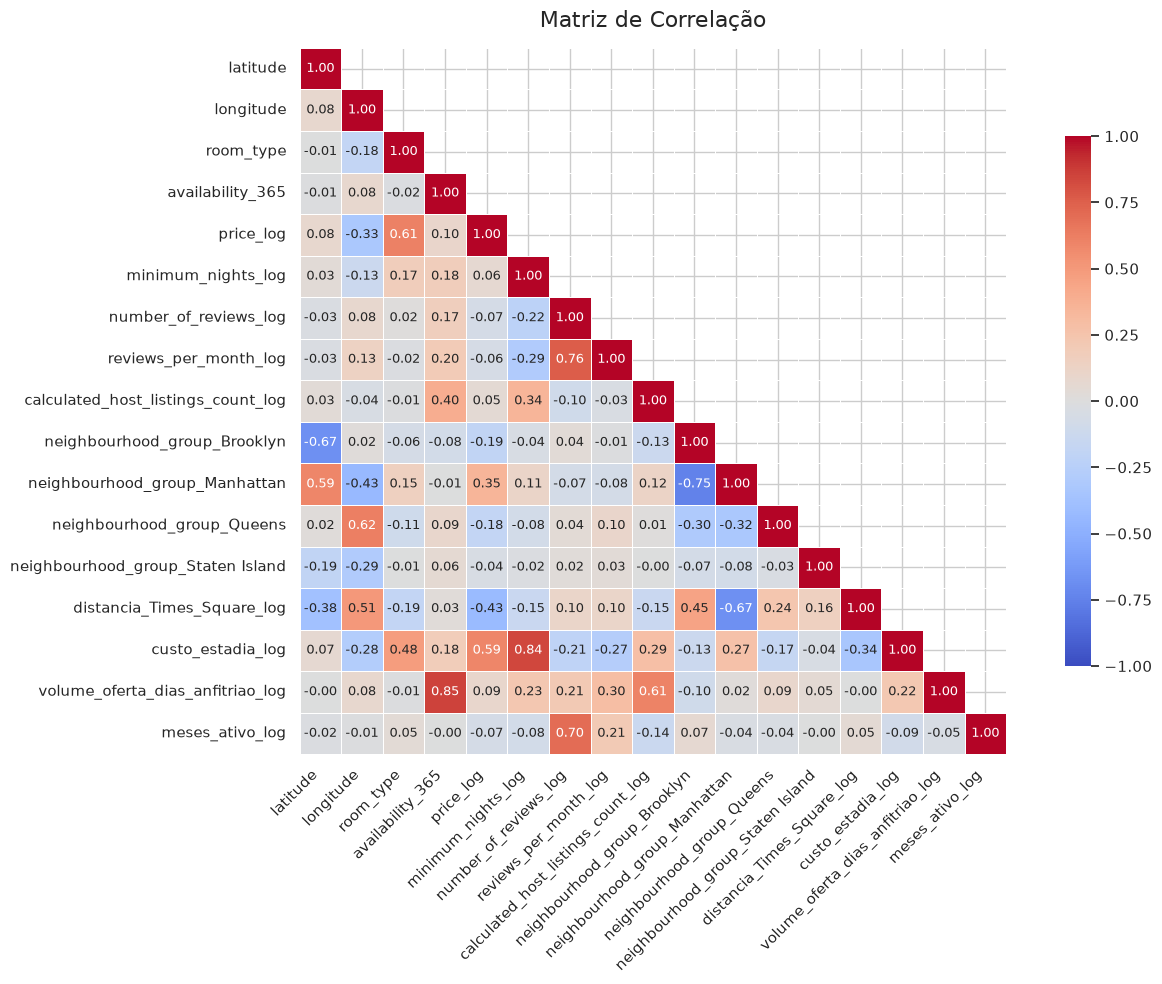

,latitude,longitude,room_type,availability_365,price_log,minimum_nights_log,number_of_reviews_log,reviews_per_month_log,calculated_host_listings_count_log,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,distancia_Times_Square_log,custo_estadia_log,volume_oferta_dias_anfitriao_log,meses_ativo_log
latitude,1.000000,0.084830,-0.006599,-0.010942,0.079285,0.033024,-0.029549,-0.026547,0.032216,-0.672905,0.590663,0.017121,-0.190916,-0.377037,0.065087,-0.002328,-0.020187
longitude,0.084830,1.000000,-0.184192,0.082669,-0.325892,-0.126426,0.080318,0.134778,-0.042289,0.017622,-0.433465,0.622848,-0.291851,0.505385,-0.278861,0.078939,-0.009532
room_type,-0.006599,-0.184192,1.000000,-0.022381,0.612369,0.173755,0.015243,-0.020252,-0.010347,-0.062608,0.149037,-0.106950,-0.007772,-0.185348,0.477053,-0.014452,0.046135
availability_365,-0.010942,0.082669,-0.022381,1.000000,0.099179,0.178319,0.171024,0.197398,0.398298,-0.079736,-0.005387,0.087125,0.057890,0.025043,0.182312,0.853862,-0.004401
price_log,0.079285,-0.325892,0.612369,0.099179,1.000000,0.064006,-0.065949,-0.060880,0.050518,-0.192112,0.347825,-0.184313,-0.044468,-0.425828,0.586705,0.092005,-0.065609
minimum_nights_log,0.033024,-0.126426,0.173755,0.178319,0.064006,1.000000,-0.220983,-0.294529,0.344087,-0.041669,0.110997,-0.080701,-0.022558,-0.147969,0.841296,0.233375,-0.083833
number_of_reviews_log,-0.029549,0.080318,0.015243,0.171024,-0.065949,-0.220983,1.000000,0.760679,-0.095925,0.035408,-0.072219,0.041467,0.024758,0.104231,-0.207201,0.213708,0.700764
reviews_per_month_log,-0.026547,0.134778,-0.020252,0.197398,-0.060880,-0.294529,0.760679,1.000000,-0.033737,-0.008126,-0.075048,0.099337,0.034122,0.104325,-0.272500,0.296318,0.209530
calculated_host_listings_count_log,0.032216,-0.042289,-0.010347,0.398298,0.050518,0.344087,-0.095925,-0.033737,1.000000,-0.131076,0.124256,0.013757,-0.001517,-0.148241,0.286094,0.605915,-0.138840
neighbourhood_group_Brooklyn,-0.672905,0.017622,-0.062608,-0.079736,-0.192112,-0.041669,0.035408,-0.008126,-0.131076,1.000000,-0.745219,-0.302508,-0.073260,0.446528,-0.127159,-0.100545,0.066702


In [194]:
plot_matriz_correlacao(df_tratado,titulo = 'Matriz de Correlação', triangulo = True)

In [195]:
# Diagnóstico de pares colineares usando o limite configurado em configs.yaml:
# collinearity_threshold = 0.7 (identifica pares de variáveis com |r de Pearson| >= 0.70,
# evitando que informações redundantes recebam peso duplicado no cálculo de distância euclidiana)
analisar_multicolinearidade_pares(df_tratado, limite=cfg["preprocessing"]["collinearity_threshold"])


--- Pares com Correlação > 0.7 ---
availability_365 & volume_oferta_dias_anfitriao_log: 0.854
minimum_nights_log & custo_estadia_log: 0.841
number_of_reviews_log & reviews_per_month_log: 0.761
neighbourhood_group_Brooklyn & neighbourhood_group_Manhattan: 0.745
number_of_reviews_log & meses_ativo_log: 0.701


### Critério de Seleção e Descarte de Variáveis Colineares (`|r| >= 0.70`)

> Como o problema é **não supervisionado** (não há variável *target* para calcular *Information Value* — IV), adotamos o critério de **preservar as features engenheiradas/compostas** (que sintetizam mais informação de negócio) e descartar as variáveis primárias redundantes (`drop_collinear_cols` no `configs.yaml`):
>
> 1. **Remover `minimum_nights_log`** ($r = 0.82$ com `custo_estadia_log`): mantemos `custo_estadia_log` e `price_log`, que já capturam tanto o valor da diária quanto o peso da exigência de noites mínimas no bolso do cliente.
> 2. **Remover `calculated_host_listings_count_log`** ($r \ge 0.70$ com `volume_oferta_dias_anfitriao_log`): mantemos `volume_oferta_dias_anfitriao_log`, que pondera o tamanho do portfólio do host pela disponibilidade efetiva no ano.
> 3. **Remover `number_of_reviews_log`** ($r = 0.90$ com `meses_ativo_log` e $r = 0.72$ com `reviews_per_month_log`): mantemos `reviews_per_month_log` (intensidade/giro mensal) e `meses_ativo_log` (maturidade histórica).
> 4. **Manter coordenadas e dummies geográficas:** Embora `latitude`/`longitude` apresentem correlação natural com os distritos, `latitude` e `longitude` serão separadas em `X_geo` na etapa de modelagem (usadas apenas para mapas), enquanto as dummies de bairro e `distancia_Times_Square_log` permanecem no modelo.


In [196]:
# Remoção das 3 variáveis colineares definidas em configs.yaml:
# drop_collinear_cols = [
#     "minimum_nights_log",
#     "calculated_host_listings_count_log",
#     "number_of_reviews_log"
# ]
colunas_remov_corr = cfg["preprocessing"]["drop_collinear_cols"]
df_tratado = df_tratado.drop(columns=colunas_remov_corr)


In [197]:
df_tratado.info()

<class 'pandas.DataFrame'>
Index: 48884 entries, 0 to 48894
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   latitude                           48884 non-null  float64
 1   longitude                          48884 non-null  float64
 2   room_type                          48884 non-null  int64  
 3   availability_365                   48884 non-null  int64  
 4   price_log                          48884 non-null  float64
 5   reviews_per_month_log              48884 non-null  float64
 6   neighbourhood_group_Brooklyn       48884 non-null  int64  
 7   neighbourhood_group_Manhattan      48884 non-null  int64  
 8   neighbourhood_group_Queens         48884 non-null  int64  
 9   neighbourhood_group_Staten Island  48884 non-null  int64  
 10  distancia_Times_Square_log         48884 non-null  float64
 11  custo_estadia_log                  48884 non-null  float64
 12  volume

> **Resumo da Base Final Exportada (`data/processed/master.csv` — 48.884 linhas × 14 colunas):**
>
> - **2 Coordenadas Geográficas (`geo_cols`):** `latitude`, `longitude` (isoladas na modelagem para visualização espacial).
> - **12 Features Explicativas de Modelagem:**
>   - **7 Numéricas Contínuas (`numerical_model_cols`):** `availability_365`, `price_log`, `reviews_per_month_log`, `distancia_Times_Square_log`, `custo_estadia_log`, `volume_oferta_dias_anfitriao_log`, `meses_ativo_log`.
>   - **1 Categórica Ordinal:** `room_type` (`0`=Shared, `1`=Private, `2`=Entire).
>   - **4 Dummies de Distrito (`bairros_dummies`):** `neighbourhood_group_Brooklyn`, `neighbourhood_group_Manhattan`, `neighbourhood_group_Queens`, `neighbourhood_group_Staten Island` (com `Bronx` como referência `0`).


### 5.4 Exportação do Dataset Processado

>
> O dataset escalonado (`df_tratado`) é exportado para `data/processed/master.csv`.


In [198]:
# Exportação do dataset processado para a modelagem (configs.yaml):
# Destino: data/processed/master.csv
nome_processado = cfg["data"]["processed_filename"]  # "master.csv"
os.makedirs(DIR_EXP, exist_ok=True)
df_tratado.to_csv(os.path.join(DIR_EXP, nome_processado), index=False)
print(f"Dataset exportado com {df_tratado.shape[0]:,} linhas x {df_tratado.shape[1]} colunas")


Dataset exportado com 48,884 linhas x 14 colunas
